In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from db import get_engine

engine = get_engine()

Bankda qalan ve geden müştərilər

In [2]:
df = pd.read_sql("SELECT * FROM gold.churn_summary", engine)

df

,churned,say,faiz
0,0,3992,79.84
1,1,1008,20.16


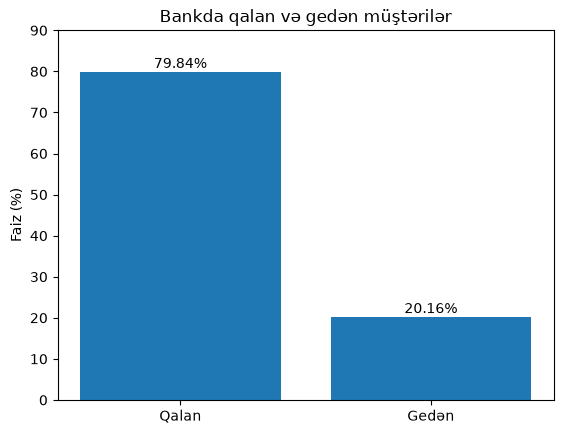

In [3]:
import matplotlib.pyplot as plt

plt.bar(["Qalan", "Gedən"], df["faiz"])

plt.title("Bankda qalan və gedən müştərilər")
plt.ylabel("Faiz (%)")

for i, faiz in enumerate(df["faiz"]):
    plt.text(i, faiz + 1, f"{faiz}%", ha="center")

plt.ylim(0, 90)
plt.show()

In [6]:
aktivlik_report = pd.read_sql(
    "SELECT * FROM gold.churn_by_activity",
    engine
)

aktivlik_report

,Aktivlik,Müştəri sayı,Bankı tərk edənlər,Churn faizi
0,Aktiv deyil,2029,584,28.78
1,Aktivdir,2971,424,14.27


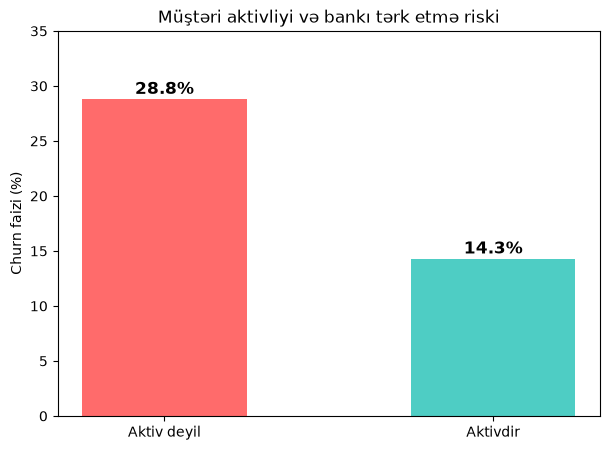

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

bars = plt.bar(
    aktivlik_report["Aktivlik"],
    aktivlik_report["Churn faizi"],
    color=["#FF6B6B", "#4ECDC4"],
    width=0.5
)

plt.title("Müştəri aktivliyi və bankı tərk etmə riski")
plt.ylabel("Churn faizi (%)")
plt.ylim(0, 35)

for bar in bars:
    faiz = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        faiz + 0.5,
        f"{faiz:.1f}%",
        ha="center",
        fontsize=12,
        fontweight="bold"
    )

plt.show()

aktiv olmayan müştərilərdə churn faizi təxminən 2 dəfə yüksəkdir.

In [8]:
products_report = pd.read_sql(
    "SELECT * FROM gold.churn_by_products",
    engine
)

products_report

,Məhsul sayı,Müştəri sayı,Bankı tərk edənlər,Churn faizi
0,1,2289,520,22.72
1,2,2114,214,10.12
2,3,441,171,38.78
3,4,156,103,66.03


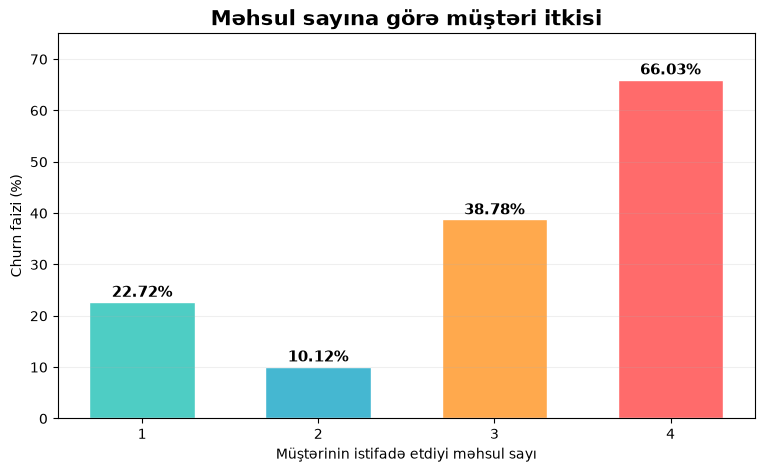

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

df_mehsul = pd.read_sql(
    "SELECT * FROM gold.churn_by_products",
    engine
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    df_mehsul["Məhsul sayı"].astype(str),
    df_mehsul["Churn faizi"],
    color=["#4ECDC4", "#45B7D1", "#FFA94D", "#FF6B6B"],
    width=0.6,
    edgecolor="white"
)

for bar in bars:
    faiz = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        faiz + 1,
        f"{faiz:.2f}%",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title("Məhsul sayına görə müştəri itkisi", fontsize=15, fontweight="bold")
plt.xlabel("Müştərinin istifadə etdiyi məhsul sayı")
plt.ylabel("Churn faizi (%)")
plt.ylim(0, 75)
plt.grid(axis="y", alpha=0.2)
plt.show()

4 mehsulu olan daha cox gedib/

In [12]:
churn_products_activity_df = pd.read_sql(
    "SELECT * FROM gold.churn_products_activity",
    engine
)

churn_products_activity_df

,say,gedən,churn_faizi
0,1037,328,31.63
1,1252,192,15.34
2,787,133,16.90
3,1327,81,6.10
4,146,75,51.37
5,295,96,32.54
6,59,48,81.36
7,97,55,56.70


In [13]:
import matplotlib.pyplot as plt

qrafik = churn_products_activity_df.pivot(
    index="products_count",
    columns="is_active",
    values="churn_faizi"
)

ax = qrafik.plot(
    kind="bar",
    figsize=(9, 5),
    color=["#FF6B6B", "#4ECDC4"],
    width=0.7
)

plt.title("Məhsul sayı və aktivliyə görə müştəri itkisi")
plt.xlabel("Məhsul sayı")
plt.ylabel("Churn faizi (%)")
plt.xticks(rotation=0)
plt.legend(["Aktiv deyil", "Aktivdir"])
plt.ylim(0, 100)

for bar in ax.patches:
    faiz = bar.get_height()
    ax.annotate(
        f"{faiz:.1f}%",
        (bar.get_x() + bar.get_width()/2, faiz),
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.show()

KeyError: 'products_count'

In [14]:
churn_products_activity_df.columns

Index(['say', 'gedən', 'churn_faizi'], dtype='str')